# SPX TimeDiff：大幅下跌條件實驗

沿用無 mixup 版本重新訓練 AR 500 步、diffusion 2,000 步，seed 2024；加入三組 21 日暴跌條件。
市場條件 loss 與 CFG 仍未啟用。原有四組條件加上 **報酬 -10%／波動率 40%、-20%／60%、-30%／80%**，
共七組，各生成 200 條路徑，並使用既有 mixup checkpoint 對相同七組條件重新取樣比較。

訓練資料、切分與標記皆不變；新增的是推論情境。報酬為 21 日累積簡單報酬，波動率為年化每日 log return 標準差。
這兩個統計量不構成完整分布定義；圖表檢查統計量是否集中在目標附近，不假設常態分布。

歷史截止日固定 2023-12-29；訓練至 2021 年底、驗證至 2023 年底，2024 年不參與選模。
兩模型各自採用相同驗證規則選出的 checkpoint。單一歷史窗口與 seed 只提供開發診斷，不能據此判定 RL 改善。
條件越極端，越需要檢查訓練資料支持；同 seed 的兩種訓練不代表所有 batch 與訓練噪聲相同。


## 1. 資料來源與重跑方式

在 app 終端執行 `bash scripts/run_spx_crash.sh`，可觀看全部階段的 tqdm，並留存 run.log。
預設結果目錄為 `outputs/spx/crash_20260929`；重跑請給新的名稱，例如 `bash scripts/run_spx_crash.sh crash_repeat2`。
腳本會用環境變數 `SPX_CRASH_RUN` 指定該輪路徑；手動執行 notebook 時可在下格修改 RUN_DIR。

Notebook 讀取現成結果，不會自行重訓。命中標準沿用：報酬 ±2 個百分點、年化波動率 ±5 個百分點，須同時滿足。
原始 mixup 模型沿用先前 checkpoint，本輪只重新取樣；無 mixup 模型會重新訓練。


In [1]:
from pathlib import Path
import json
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'spx_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('請從 TimeDiff 或其子目錄啟動 notebook')
RUN_DIR = Path(os.environ.get('SPX_CRASH_RUN', ROOT/'outputs/spx/crash_20260929')).resolve()
RUNS = {
    'Mixup': {'train': ROOT/'outputs/spx/initial', 'samples': RUN_DIR/'mixup_samples'},
    'No mixup': {'train': RUN_DIR/'train', 'samples': RUN_DIR/'no_mixup_samples'},
}
COLORS = {'Mixup': '#376C9E', 'No mixup': '#C47C28'}
STYLES = {'Mixup': '--', 'No mixup': '-'}
EXPORT = RUN_DIR / 'comparison'
EXPORT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18})

loaded = {}
for label, locations in RUNS.items():
    required = [locations['train']/name for name in ['metadata.json', 'training.csv']]
    required += [locations['samples']/name for name in
                 ['sampling.json', 'paths.csv', 'path_metrics.csv', 'summary.csv', 'history_features.csv']]
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError('先完成該組 train/sample：' + ', '.join(missing))
    loaded[label] = {
        'meta': json.loads((locations['train']/'metadata.json').read_text()),
        'sampling': json.loads((locations['samples']/'sampling.json').read_text()),
        'training': pd.read_csv(locations['train']/'training.csv'),
        'paths': pd.read_csv(locations['samples']/'paths.csv'),
        'saved_metrics': pd.read_csv(locations['samples']/'path_metrics.csv'),
        'saved_summary': pd.read_csv(locations['samples']/'summary.csv'),
        'history': pd.read_csv(locations['samples']/'history_features.csv'),
    }


## 2. 確認比較設定與資料一致

確認資料指紋、切分、條件 scaler、模型設定、取樣 seed、歷史與目標條件一致。
舊版 metadata 沒有完整 CLI，因此舊版的訓練步數由 training.csv 驗證，其他未記錄欄位不能宣稱已自動驗證。

In [2]:
base, new = loaded['Mixup'], loaded['No mixup']
for key in ['data_sha256', 'train_end', 'val_end', 'seed', 'ar_steps',
            'feature_scaler', 'condition_scaler', 'split_windows']:
    assert base['meta'][key] == new['meta'][key], f'訓練設定不一致：{key}'
for key, value in base['meta']['args'].items():
    if key not in {'use_future_mixup', 'device'}:
        assert value == new['meta']['args'][key], f'模型設定不一致：{key}'
assert base['meta']['args'].get('use_future_mixup', True)
assert new['meta']['args']['use_future_mixup'] is False
for key in ['history_end', 'seed', 'n_paths', 'conditions', 'return_tolerance', 'volatility_tolerance']:
    assert base['sampling'][key] == new['sampling'][key], f'取樣設定不一致：{key}'
pd.testing.assert_frame_equal(base['history'], new['history'])
np.testing.assert_array_equal(base['training']['step'], new['training']['step'])
assert base['training']['step'].max() == new['training']['step'].max() == 2000
price_path = ROOT / 'datasets/spx/prices.csv'
if price_path.exists():
    assert hashlib.sha256(price_path.read_bytes()).hexdigest() == new['meta']['data_sha256']

targets = np.asarray(new['sampling']['conditions'])
TOL_R = new['sampling']['return_tolerance']
TOL_V = new['sampling']['volatility_tolerance']
provenance = pd.DataFrame([{
    'method': label, 'mixup': d['meta']['args'].get('use_future_mixup', True),
    'best_step': d['meta']['best_step'],
    'validation_condition_mse': d['meta']['best_validation_condition_mse'],
    'train_seed': d['meta']['seed'], 'sampling_seed': d['sampling']['seed'],
    'history_end': d['sampling']['history_end'], 'paths_per_condition': d['sampling']['n_paths'],
    'code_commit': d['meta'].get('code_commit', '未記錄（舊版）'),
} for label, d in loaded.items()])
display(provenance)


,method,mixup,best_step,validation_condition_mse,train_seed,sampling_seed,history_end,paths_per_condition,code_commit
0,Mixup,True,100,1.049102,2024,2024,2023-12-29,200,未記錄（舊版）
1,No mixup,False,900,0.485747,2024,2024,2023-12-29,200,30bbb731131cc1cbaa9c7cc87130f767e24c0ffa


## 3. 由原始路徑重算指標

使用 21 個每日 log return，包含歷史最後收盤到第一個生成日的報酬：

- 累積報酬：`expm1(sum(rclose))`。
- 年化波動率：`std(rclose, ddof=1) * sqrt(252)`。
- MAE：每條路徑與指定條件的絕對差，再跨路徑平均。

先重算每條路徑，再核對已儲存的 metrics 與 summary。沒有先平均價格路徑才計算波動率。
5%–95% 是生成樣本的分位數區間，不是平均值的信賴區間。

In [3]:
metric_frames, rows = [], []
for label, data in loaded.items():
    paths = data['paths'].sort_values(['scenario', 'path', 'step'])
    assert not paths.duplicated(['scenario', 'path', 'step']).any()
    assert np.isfinite(paths.select_dtypes('number')).all().all()
    assert (paths.low <= paths.close).all() and (paths.close <= paths.high).all()
    groups = paths.groupby(['scenario', 'path'], sort=True)
    assert groups.size().eq(21).all()
    assert groups['step'].apply(lambda x: np.array_equal(x, np.arange(1, 22))).all()
    stats = groups['rclose'].agg(
        actual_return=lambda r: np.expm1(r.sum()),
        actual_volatility=lambda r: r.std(ddof=1)*np.sqrt(252),
    ).reset_index()
    saved = data['saved_metrics'].sort_values(['scenario', 'path']).reset_index(drop=True)
    np.testing.assert_array_equal(stats[['scenario', 'path']], saved[['scenario', 'path']])
    np.testing.assert_allclose(stats[['actual_return', 'actual_volatility']],
                               saved[['return', 'volatility']], rtol=1e-5, atol=1e-7)
    stats['method'] = label
    stats['target_return'] = targets[stats.scenario.to_numpy(), 0]
    stats['target_volatility'] = targets[stats.scenario.to_numpy(), 1]
    stats['return_error'] = stats.actual_return - stats.target_return
    stats['volatility_error'] = stats.actual_volatility - stats.target_volatility
    stats['hit'] = (stats.return_error.abs() <= TOL_R) & (stats.volatility_error.abs() <= TOL_V)
    np.testing.assert_array_equal(stats['hit'], saved['hit'])
    metric_frames.append(stats)
    for scenario, g in stats.groupby('scenario'):
        p = paths[paths.scenario == scenario]
        assert len(g) == data['sampling']['n_paths']
        np.testing.assert_allclose(p[['target_return', 'target_volatility']],
                                   np.tile(targets[scenario], (len(p), 1)))
        row = dict(method=label, scenario=scenario, n=len(g),
                   target_return=targets[scenario, 0], target_volatility=targets[scenario, 1],
                   return_mean=g.actual_return.mean(), volatility_mean=g.actual_volatility.mean(),
                   return_mae=g.return_error.abs().mean(), volatility_mae=g.volatility_error.abs().mean(),
                   return_p05=g.actual_return.quantile(.05), return_p95=g.actual_return.quantile(.95),
                   volatility_p05=g.actual_volatility.quantile(.05), volatility_p95=g.actual_volatility.quantile(.95),
                   joint_hit_rate=g.hit.mean(), rhigh_clip_rate=(p.rhigh_raw < 0).mean(),
                   rlow_clip_rate=(p.rlow_raw > 0).mean())
        saved_row = data['saved_summary'].set_index('scenario').loc[scenario]
        for key in row.keys() - {'method', 'scenario', 'n'}:
            np.testing.assert_allclose(row[key], saved_row[key], rtol=1e-5, atol=1e-7)
        rows.append(row)
metrics = pd.concat(metric_frames, ignore_index=True)
summary = pd.DataFrame(rows).sort_values(['scenario', 'method'])
summary.to_csv(EXPORT/'comparison_summary.csv', index=False)
cols = ['method', 'scenario', 'n', 'target_return', 'target_volatility', 'return_mean',
        'volatility_mean', 'return_mae', 'volatility_mae', 'joint_hit_rate', 'rhigh_clip_rate', 'rlow_clip_rate']
display(summary[cols].style.format({k: '{:.2%}' for k in cols if k not in {'method', 'scenario', 'n'}}))


,method,scenario,n,target_return,target_volatility,return_mean,volatility_mean,return_mae,volatility_mae,joint_hit_rate,rhigh_clip_rate,rlow_clip_rate
0,Mixup,0,200,-5.00%,15.00%,-1.17%,14.81%,4.92%,2.09%,25.50%,22.24%,24.93%
7,No mixup,0,200,-5.00%,15.00%,-4.34%,14.89%,2.78%,1.74%,42.50%,8.88%,15.52%
1,Mixup,1,200,5.00%,15.00%,6.03%,14.31%,4.31%,2.05%,25.50%,31.43%,20.05%
8,No mixup,1,200,5.00%,15.00%,2.64%,14.23%,3.64%,1.79%,28.50%,15.21%,10.71%
2,Mixup,2,200,-5.00%,35.00%,4.32%,16.58%,9.47%,18.42%,0.00%,26.00%,12.86%
9,No mixup,2,200,-5.00%,35.00%,-4.74%,28.76%,3.98%,6.37%,14.50%,7.86%,12.57%
3,Mixup,3,200,5.00%,35.00%,11.19%,16.06%,6.94%,18.94%,0.00%,26.81%,7.57%
10,No mixup,3,200,5.00%,35.00%,4.33%,26.25%,4.43%,8.75%,5.50%,8.62%,8.48%
4,Mixup,4,200,-10.00%,40.00%,2.92%,17.21%,12.97%,22.79%,0.00%,26.45%,13.29%
11,No mixup,4,200,-10.00%,40.00%,-10.26%,35.37%,4.06%,5.35%,18.00%,7.81%,14.36%


## 4. 各條件的統計量分布

每列一個指定條件，兩組使用同一組 bins；每欄共用尺度，避免視覺上誇大差異。
黑色虛線是目標，灰色區域是容許誤差。柱形顯示實際路徑數，不假設分布形狀。

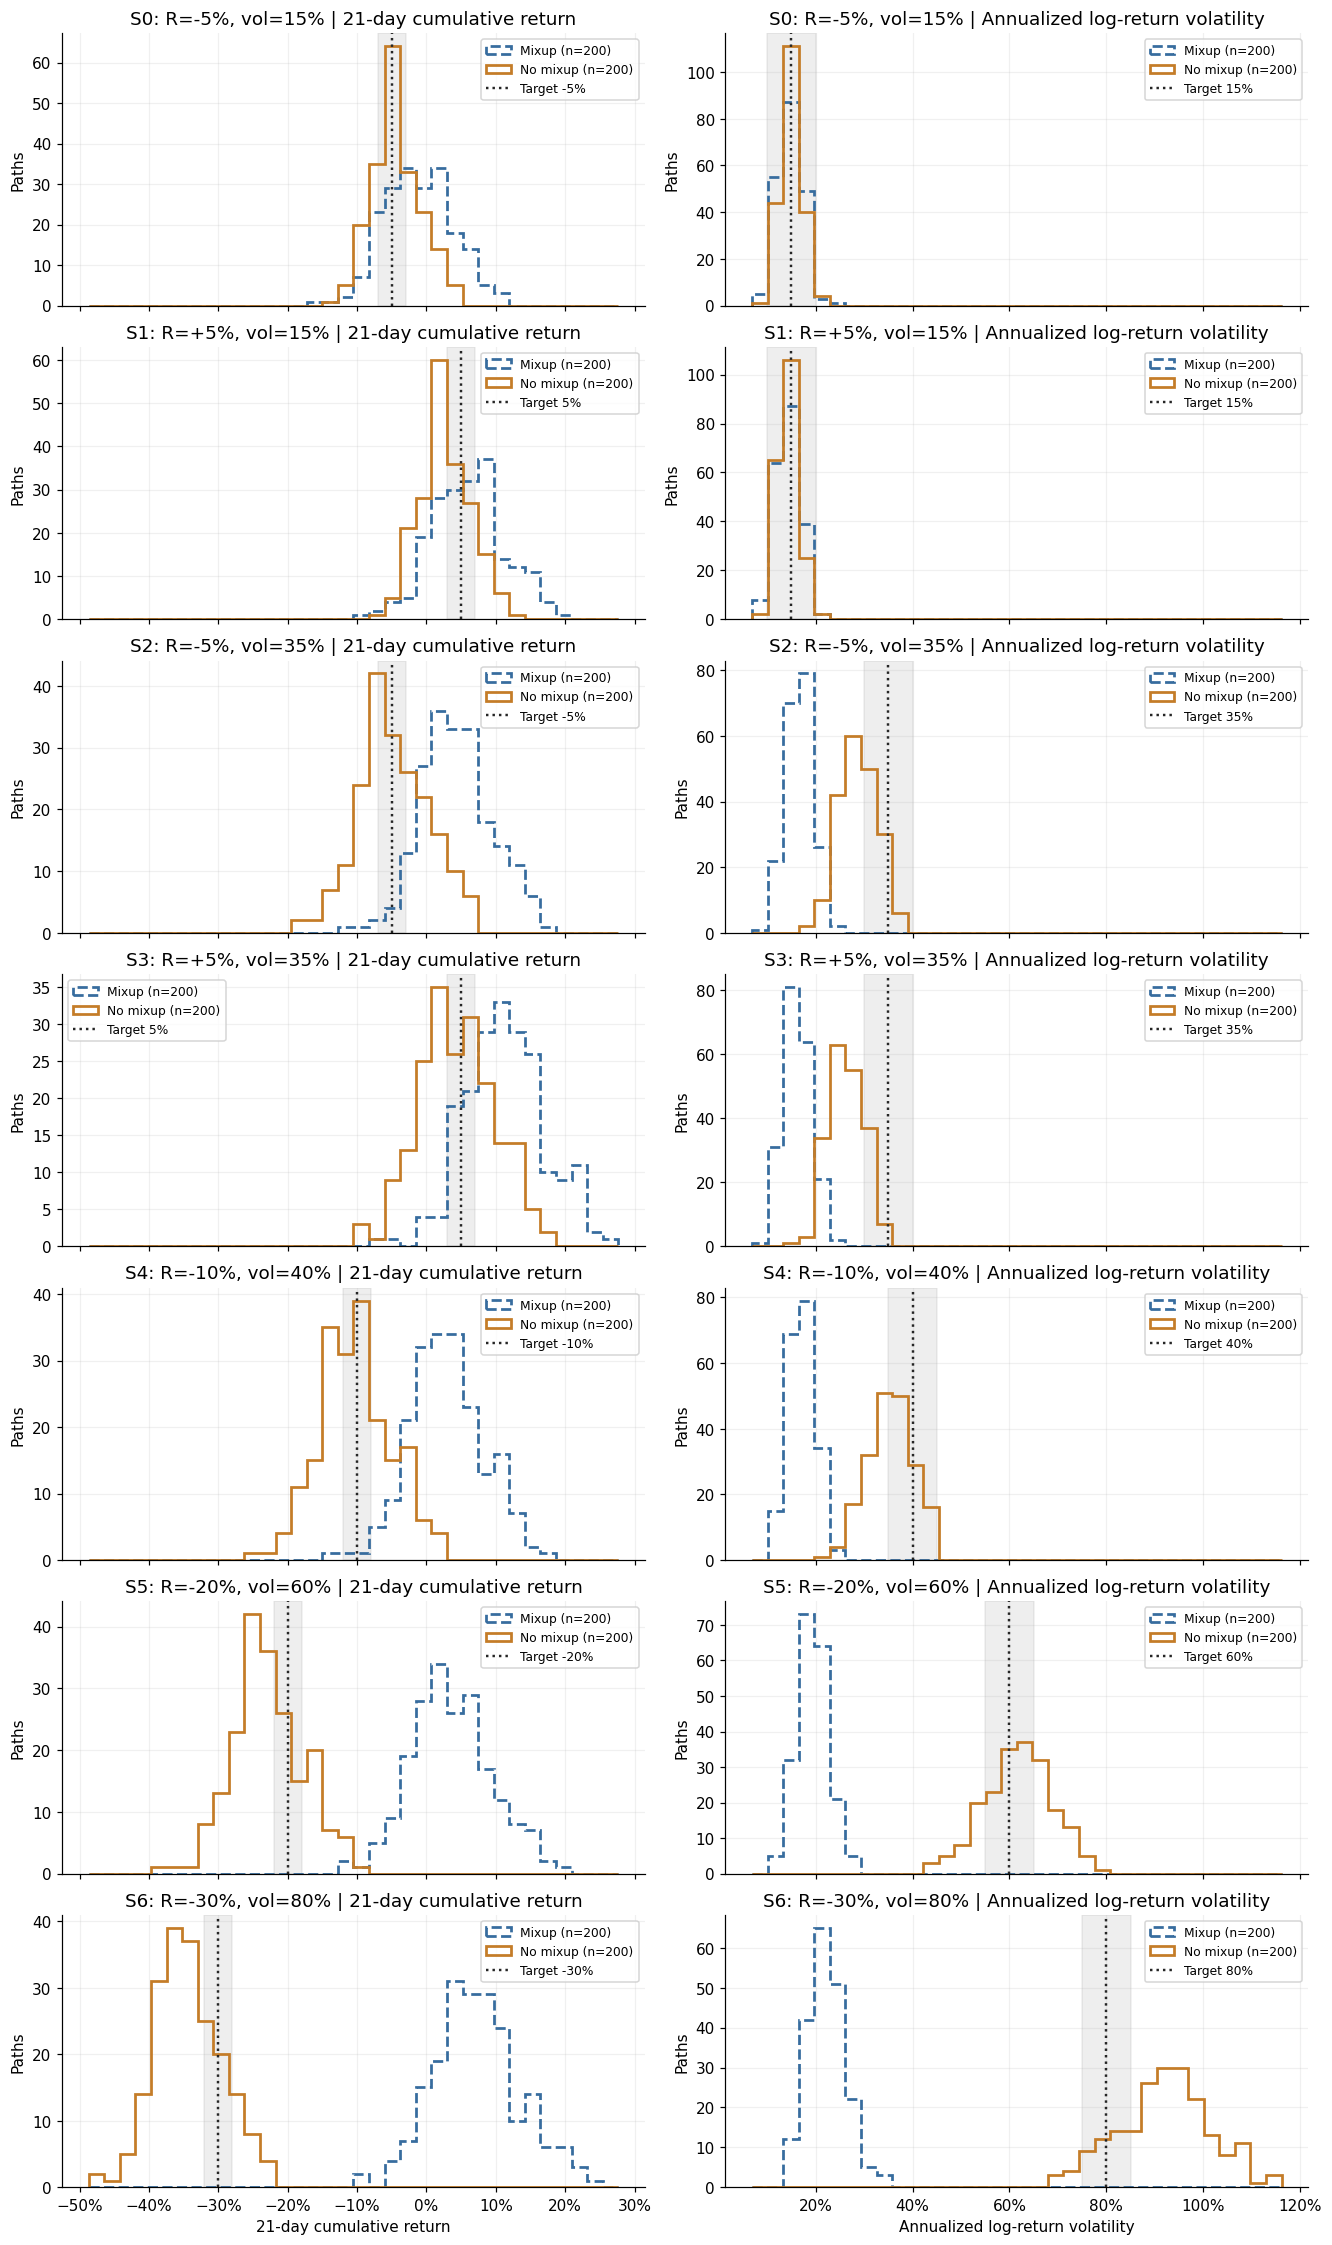

In [4]:
fig, axes = plt.subplots(len(targets), 2, figsize=(12, 2.9*len(targets)), sharex='col', constrained_layout=True)
for j, (metric, tolerance, title) in enumerate([
    ('actual_return', TOL_R, '21-day cumulative return'),
    ('actual_volatility', TOL_V, 'Annualized log-return volatility'),
]):
    lower = min(metrics[metric].min(), (targets[:, j]-tolerance).min())
    upper = max(metrics[metric].max(), (targets[:, j]+tolerance).max())
    bins = np.linspace(lower-.01, upper+.01, 35)
    for scenario in range(len(targets)):
        ax = axes[scenario, j]
        target = targets[scenario, j]
        ax.axvspan(target-tolerance, target+tolerance, color='#777777', alpha=.12)
        for label in RUNS:
            values = metrics.loc[(metrics.method == label) & (metrics.scenario == scenario), metric]
            ax.hist(values, bins=bins, histtype='step', linewidth=1.8,
                    color=COLORS[label], linestyle=STYLES[label], label=f'{label} (n={len(values)})')
        ax.axvline(target, color='#252525', linestyle=':', linewidth=1.6, label=f'Target {target:.0%}')
        ax.set_title(f'S{scenario}: R={targets[scenario, 0]:+.0%}, vol={targets[scenario, 1]:.0%} | {title}')
        ax.set_ylabel('Paths')
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(fontsize=8)
        if scenario == len(targets)-1:
            ax.set_xlabel(title)
fig.savefig(EXPORT/'condition_histograms.png', dpi=150)
plt.show()


## 5. 聯合符合度

報酬與波動率必須在同一條路徑同時符合目標。十字是指定條件，灰色矩形是聯合命中範圍。
各子圖共用座標尺度；單獨看兩個邊際平均值可能掩蓋未命中的路徑。

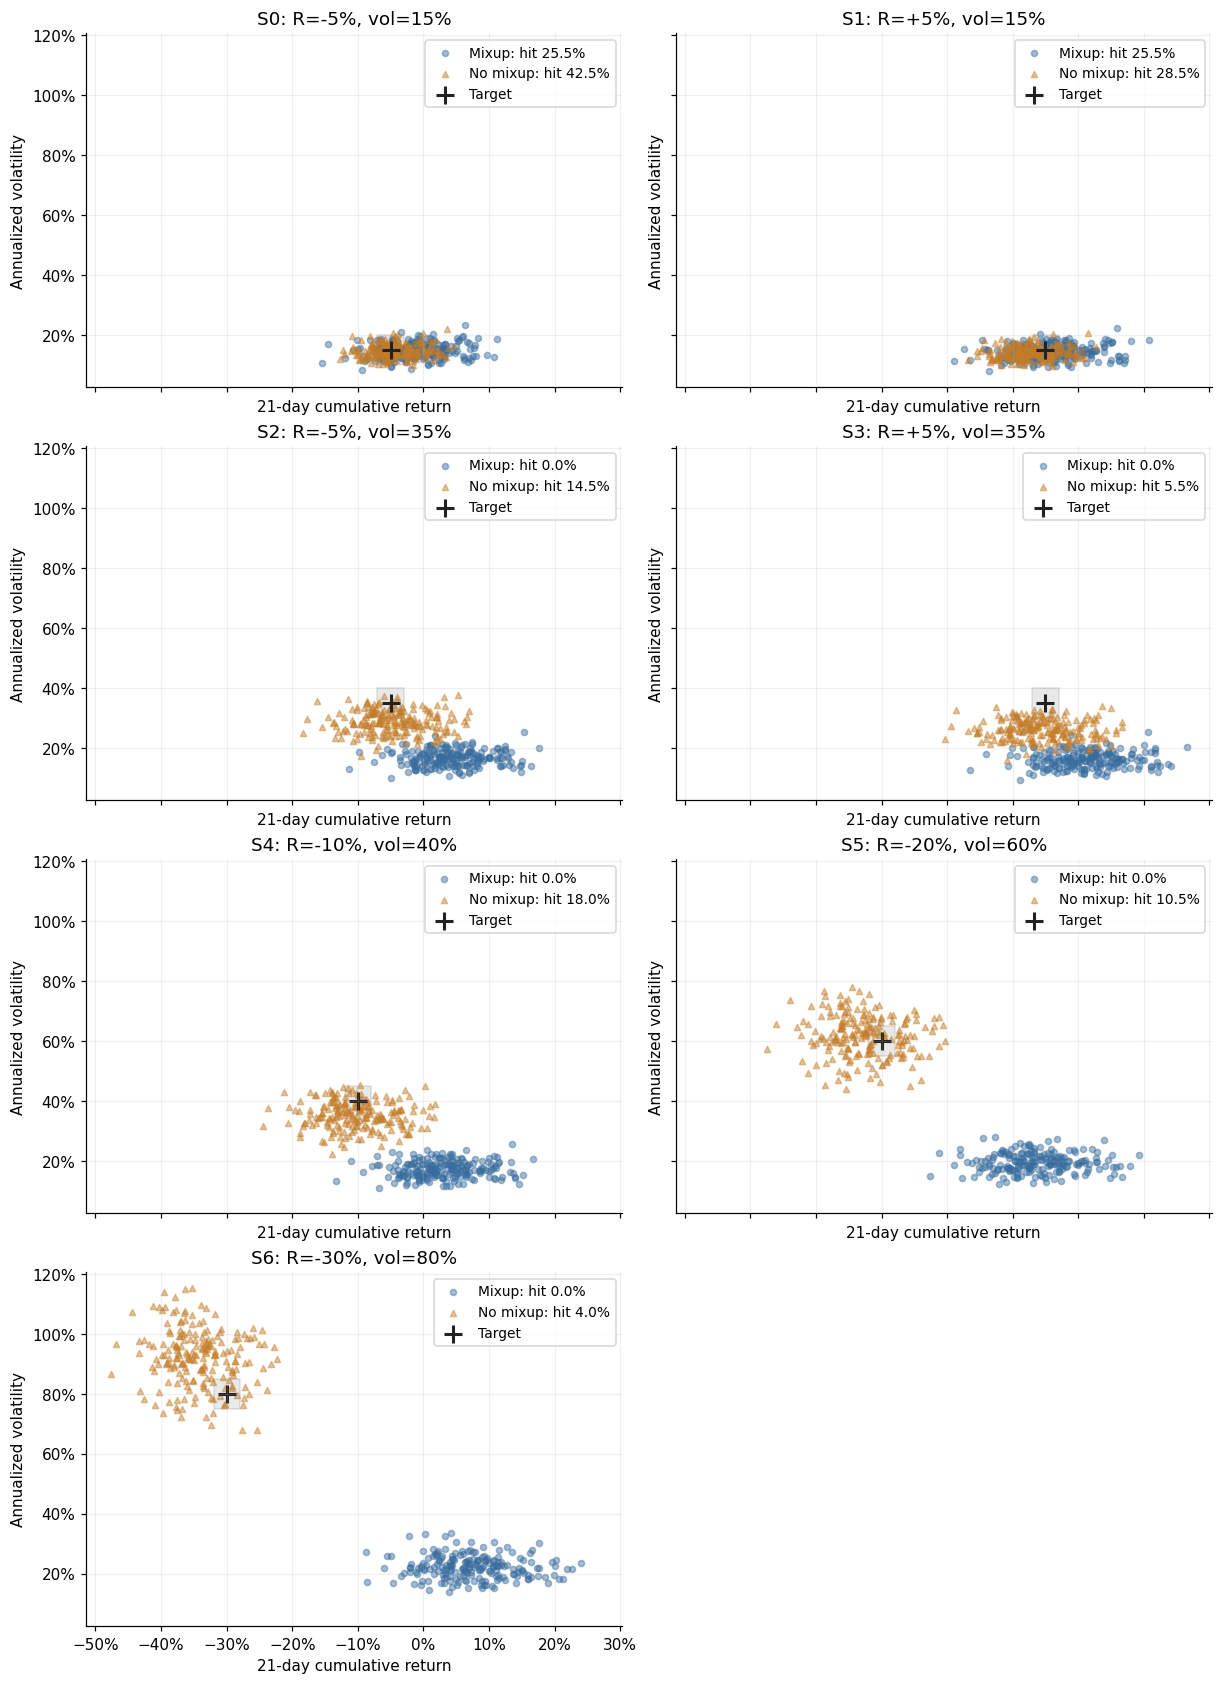

In [5]:
fig, axes = plt.subplots((len(targets)+1)//2, 2, figsize=(11, 3.8*((len(targets)+1)//2)), sharex=True, sharey=True, constrained_layout=True)
for scenario, ax in enumerate(axes.flat):
    if scenario >= len(targets):
        ax.set_visible(False)
        continue
    r, v = targets[scenario]
    ax.add_patch(Rectangle((r-TOL_R, v-TOL_V), 2*TOL_R, 2*TOL_V,
                           facecolor='#777777', edgecolor='#555555', alpha=.16))
    for label, marker in [('Mixup', 'o'), ('No mixup', '^')]:
        g = metrics[(metrics.method == label) & (metrics.scenario == scenario)]
        ax.scatter(g.actual_return, g.actual_volatility, color=COLORS[label], marker=marker,
                   s=16, alpha=.45, label=f'{label}: hit {g.hit.mean():.1%}')
    ax.scatter([r], [v], color='#222222', marker='+', s=150, linewidths=2, label='Target')
    ax.set_title(f'S{scenario}: R={r:+.0%}, vol={v:.0%}')
    ax.set_xlabel('21-day cumulative return')
    ax.set_ylabel('Annualized volatility')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=9)
fig.savefig(EXPORT/'joint_conditions.png', dpi=150)
plt.show()


## 6. 訓練曲線與選模

訓練 loss 是記錄步數當下的一個 batch，並非 epoch 平均。驗證分數來自完整採樣後的條件誤差，越低越好。
兩組各自採用最佳驗證 checkpoint；標記點顯示選中的步數。驗證只涵蓋前 4 個 batch，不代表整個驗證期間。

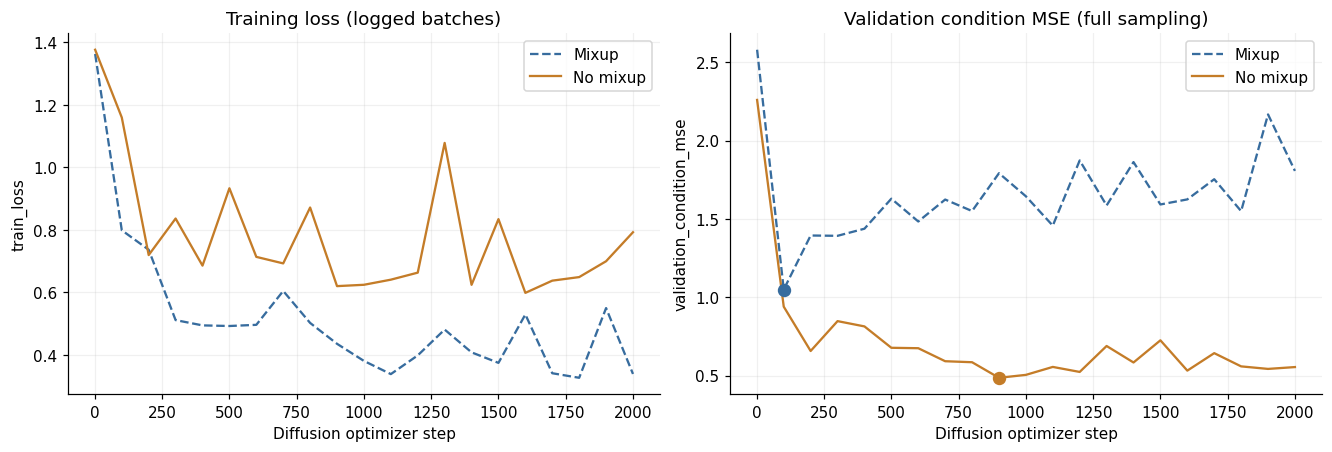

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for label, data in loaded.items():
    log = data['training']
    for ax, column in zip(axes, ['train_loss', 'validation_condition_mse']):
        ax.plot(log.step, log[column], color=COLORS[label], linestyle=STYLES[label], label=label)
        ax.set_xlabel('Diffusion optimizer step')
        ax.set_ylabel(column)
        ax.legend()
    best = data['meta']['best_step']
    score = data['meta']['best_validation_condition_mse']
    axes[1].scatter([best], [score], color=COLORS[label], s=60, zorder=5)
axes[0].set_title('Training loss (logged batches)')
axes[1].set_title('Validation condition MSE (full sampling)')
fig.savefig(EXPORT/'training_curves.png', dpi=150)
plt.show()


## 7. 路徑樣貌與限制

每組只畫編號 0–9 的路徑，避免挑選看起來較好的樣本。起點指數設為 100；虛線終點為指定累積報酬。
此圖只協助觀察形狀，不能取代尾端、波動聚集、回撤等市場真實性檢查。
OHLC 符號修正比例已列於上表：修正後價格合法不等於原始生成品質合格。

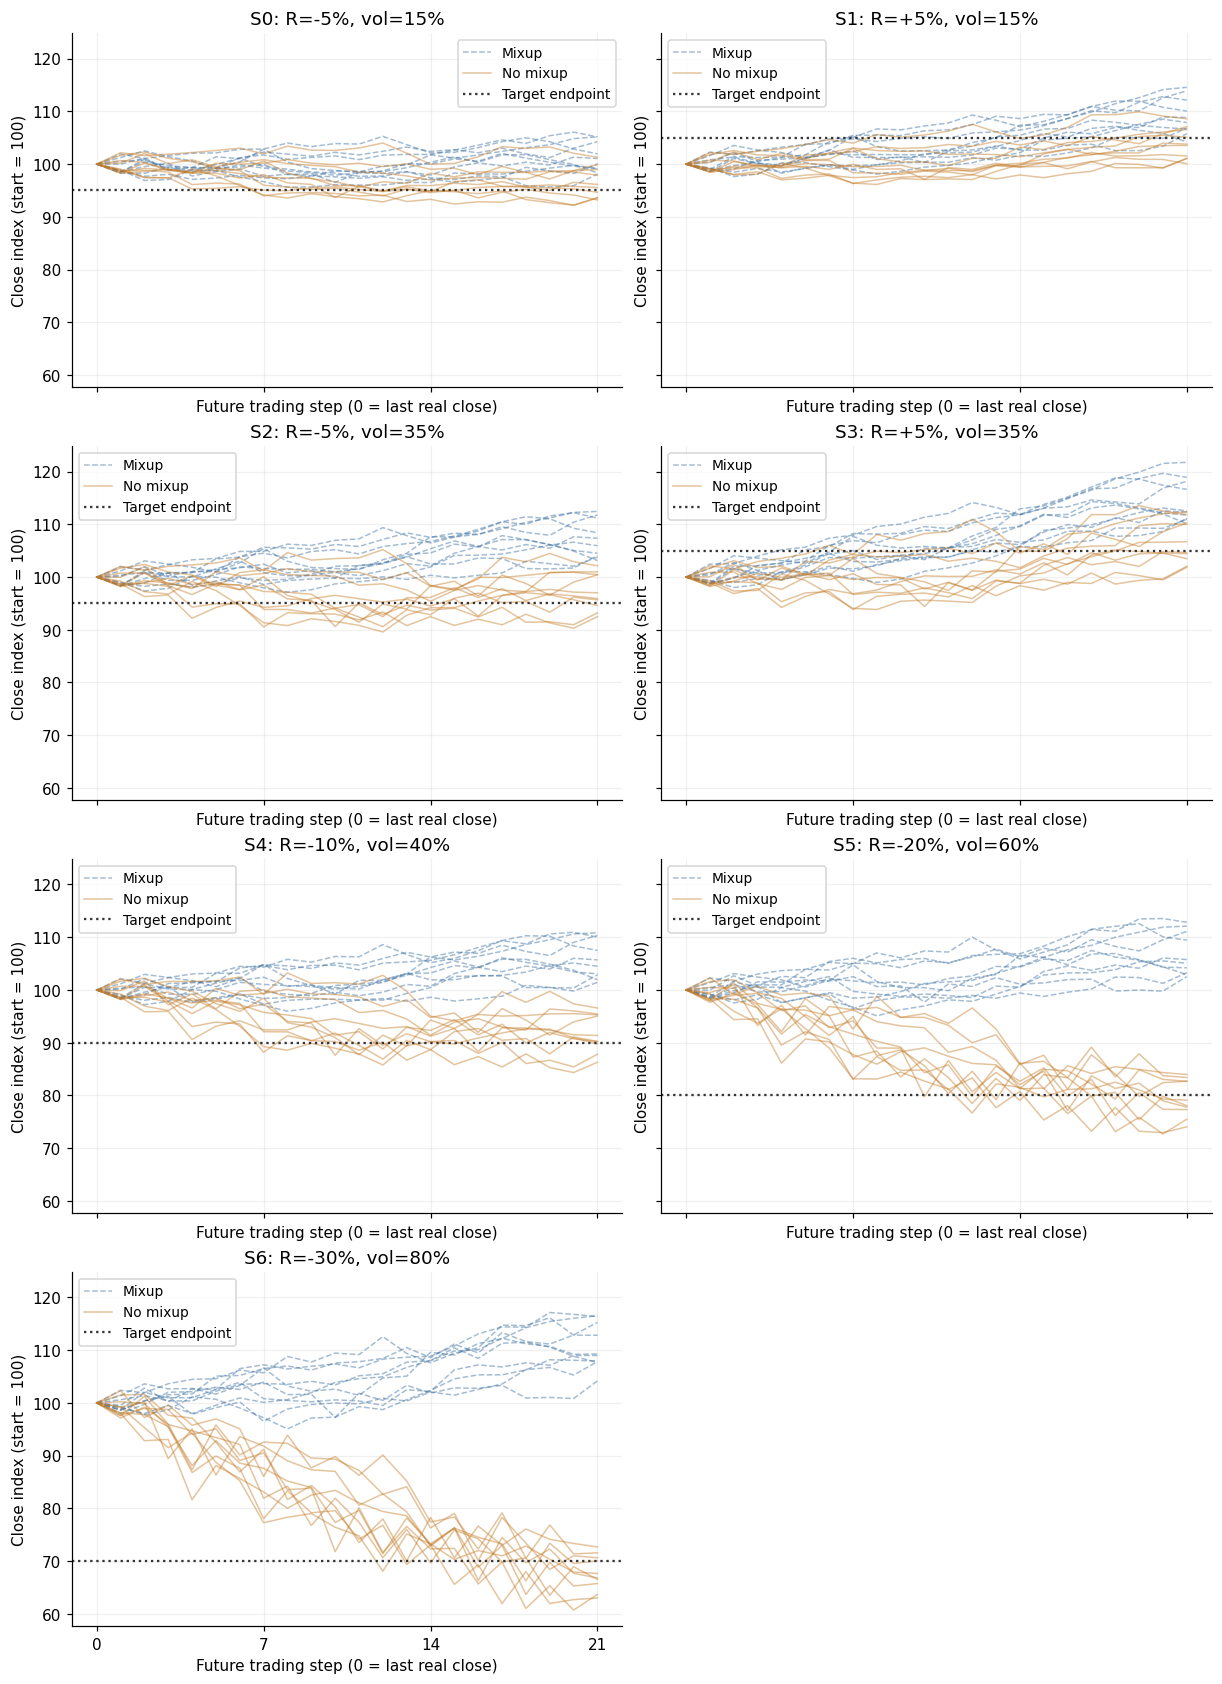

In [7]:
fig, axes = plt.subplots((len(targets)+1)//2, 2, figsize=(11, 3.8*((len(targets)+1)//2)), sharex=True, sharey=True, constrained_layout=True)
for scenario, ax in enumerate(axes.flat):
    if scenario >= len(targets):
        ax.set_visible(False)
        continue
    for label, data in loaded.items():
        paths = data['paths']
        for path_id in range(min(10, data['sampling']['n_paths'])):
            r = paths[(paths.scenario == scenario) & (paths.path == path_id)].sort_values('step').rclose.to_numpy()
            indexed = np.r_[100., 100*np.exp(np.cumsum(r))]
            ax.plot(np.arange(22), indexed, color=COLORS[label], linestyle=STYLES[label],
                    alpha=.45, linewidth=1, label=label if path_id == 0 else None)
    ax.axhline(100*(1+targets[scenario, 0]), color='#333333', linestyle=':', label='Target endpoint')
    ax.set_title(f'S{scenario}: R={targets[scenario, 0]:+.0%}, vol={targets[scenario, 1]:.0%}')
    ax.set_xlabel('Future trading step (0 = last real close)')
    ax.set_ylabel('Close index (start = 100)')
    ax.set_xticks([0, 7, 14, 21])
    ax.legend(fontsize=9)
fig.savefig(EXPORT/'example_paths.png', dpi=150)
plt.show()


## 8. 本輪結果摘要

以下差值為「No mixup − Mixup」。MAE 差值小於零代表誤差降低；命中率差值大於零代表提升。
報酬與波動率的差值單位均為百分點（pp）。此處不把 1,400 條路徑當成 1,400 次獨立模型訓練，亦不宣稱統計顯著。

In [8]:
before = summary[summary.method == 'Mixup'].set_index('scenario')
after = summary[summary.method == 'No mixup'].set_index('scenario')
comparison = after[['target_return', 'target_volatility']].copy()
for metric in ['return_mae', 'volatility_mae', 'joint_hit_rate']:
    comparison[metric + '_delta_pp'] = 100*(after[metric]-before[metric])
display(comparison.style.format({'target_return': '{:+.0%}', 'target_volatility': '{:.0%}',
    **{k: '{:+.2f}' for k in comparison if k.endswith('_pp')}}))
overall = summary.groupby('method')[['return_mae', 'volatility_mae', 'joint_hit_rate']].mean()
display(overall.style.format('{:.2%}'))
improved_r = int((comparison.return_mae_delta_pp < 0).sum())
improved_v = int((comparison.volatility_mae_delta_pp < 0).sum())
display(Markdown(f'本輪 {len(targets)} 組條件中，報酬 MAE 降低 **{improved_r} 組**，'
                 f'波動率 MAE 降低 **{improved_v} 組**。各條件樣本數相同，上表為等權平均。'
                 '是否值得繼續採用，仍需同時檢查命中率、路徑多樣性與 OHLC 修正比例。'))
comparison.to_csv(EXPORT/'comparison_deltas.csv')
print('圖表與彙整表：', EXPORT)


圖表與彙整表： /Users/chuanwei/Files/Projects/nycu_fintech/TimeDiff/outputs/spx/crash_20260929/comparison


,target_return,target_volatility,return_mae_delta_pp,volatility_mae_delta_pp,joint_hit_rate_delta_pp
scenario,,,,,
0,-5%,15%,-2.15,-0.35,+17.00
1,+5%,15%,-0.67,-0.26,+3.00
2,-5%,35%,-5.49,-12.05,+14.50
3,+5%,35%,-2.51,-10.19,+5.50
4,-10%,40%,-8.91,-17.44,+18.00
5,-20%,60%,-18.75,-34.87,+10.50
6,-30%,80%,-31.93,-44.72,+4.00


,return_mae,volatility_mae,joint_hit_rate
method,,,
Mixup,14.22%,23.24%,7.29%
No mixup,4.16%,6.11%,17.64%


本輪 7 組條件中，報酬 MAE 降低 **7 組**，波動率 MAE 降低 **7 組**。各條件樣本數相同，上表為等權平均。是否值得繼續採用，仍需同時檢查命中率、路徑多樣性與 OHLC 修正比例。

## 9. 極端條件的歷史支持

以下只使用訓練窗口。列出目標在訓練條件二維標準化空間的最近距離，以及同一命中容許區間內的窗口數。
窗口彼此重疊，不能把窗口數當成獨立事件數。區間內有歷史樣本也不保證在目前歷史背景下合理；
零窗口代表這個局部區域沒有訓練觀測，不表示數學上不可能。報酬與波動率同步調整，無法單獨識別兩個條件的作用。


In [9]:
support = pd.read_csv(RUNS['No mixup']['train']/'train_conditions.csv')
scaler = new['meta']['condition_scaler']
mean, scale = np.array(scaler['mean']), np.array(scaler['scale'])
raw = support[['return', 'volatility']].to_numpy()
checks = []
for scenario, target in enumerate(targets):
    distance = np.linalg.norm((raw-target)/scale, axis=1)
    nearest = raw[distance.argmin()]
    inside = (np.abs(raw[:, 0]-target[0]) <= TOL_R) & (np.abs(raw[:, 1]-target[1]) <= TOL_V)
    checks.append(dict(scenario=scenario, target_return=target[0], target_volatility=target[1],
                       nearby_train_windows=int(inside.sum()), nearest_distance_z=distance.min(),
                       nearest_return=nearest[0], nearest_volatility=nearest[1]))
support_check = pd.DataFrame(checks)
support_check.to_csv(EXPORT/'training_support.csv', index=False)
display(support_check.style.format({k:'{:.1%}' for k in
    ['target_return','target_volatility','nearest_return','nearest_volatility']}))
display(support.agg(['min','max']).style.format('{:.1%}'))
# Compare the original four and newly added crash conditions separately.
by_group = summary.assign(group=np.where(summary.scenario < 4, 'Original four', 'Crash three'))
display(by_group.groupby(['group','method'])[['return_mae','volatility_mae','joint_hit_rate']].mean().style.format('{:.2%}'))


,scenario,target_return,target_volatility,nearby_train_windows,nearest_distance_z,nearest_return,nearest_volatility
0,0,-5.0%,15.0%,324,0.024725,-5.1%,15.0%
1,1,5.0%,15.0%,648,0.005797,5.0%,15.0%
2,2,-5.0%,35.0%,47,0.067117,-5.1%,35.7%
3,3,5.0%,35.0%,22,0.011445,5.0%,34.9%
4,4,-10.0%,40.0%,21,0.248942,-9.5%,37.5%
5,5,-20.0%,60.0%,2,0.193543,-19.6%,58.1%
6,6,-30.0%,80.0%,5,0.016507,-30.0%,80.2%


,return,volatility
min,-33.0%,3.5%
max,25.1%,97.6%


尚未加入條件一致性 loss 或 CFG。請先觀察新增暴跌條件的偏差、命中率、歷史支持及路徑品質，再決定下一階段。
此 notebook 可使用一般 Jupyter Run All，或 `execute_in_process.py` 逐格執行並保存輸出；後者不需要 TCP 核心。
